# 05_Results_Analysis: Đánh giá chéo, tổng hợp kết quả, xuất dữ liệu demo

**Phục vụ:** mục 4.4–4.5 của báo cáo và demo Streamlit. **Đầu vào:** `recommendations.parquet`, `pricing_config.json` (notebook 04). Không cần nạp lại mô hình.

| Phần | Nội dung |
|---|---|
| 1 | **Đánh giá chéo**: chọn giá bằng cách A, chấm điểm bằng cách B (và ngược lại), kèm ngưỡng lợi ích tối thiểu |
| 2 | Độ vững theo giá vốn |
| 3 | Bảng tổng hợp toàn bộ kết quả cho báo cáo |
| 4 | Xuất dữ liệu nhỏ gọn cho demo Streamlit |

**Vì sao cần đánh giá chéo:** nếu một chính sách chỉ tốt khi được chấm bằng chính mô hình đã chọn ra nó, lợi ích có thể chỉ là sai số của mô hình được khuếch đại (optimizer's curse). Chấm bằng một cách mô phỏng độc lập cho ước lượng thận trọng hơn.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

USE_DRIVE = True
PROJECT = "Dynamic_Pricing_Project"
MIN_GAINS = [0.0, 0.02, 0.05]       # chỉ giảm giá khi lợi nhuận dự kiến tăng ít nhất x% so với giữ giá
DEMO_PRODUCTS = 40                   # số sản phẩm đưa vào demo
DEMO_STORES_PER_PRODUCT = 25

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive") / PROJECT
    except ImportError:
        OUT_DIR = Path(PROJECT)
else:
    OUT_DIR = Path(PROJECT)
DEMO_DIR = OUT_DIR / "demo" / "data"
for p in [OUT_DIR / "figures", OUT_DIR / "tables", DEMO_DIR]:
    p.mkdir(parents=True, exist_ok=True)

C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID_C, MUTED = "#0b0b0b", "#52514e", "#e6e4df", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / "figures" / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
pct = lambda x: f"{x:+.1%}"

cfg = json.load(open(OUT_DIR / "data" / "pricing_config.json"))
GRID = np.array(cfg["grid"]); COSTS = cfg["costs"]; MAIN_COST = cfg["main_cost"]
rec = pd.read_parquet(OUT_DIR / "data" / "recommendations.parquet")
QA = rec[[f"qA_{d:.2f}" for d in GRID]].to_numpy("float64")
QB = rec[[f"qB_{d:.2f}" for d in GRID]].to_numpy("float64")
ALLOWED = rec[[f"allowed_{d:.2f}" for d in GRID]].to_numpy(bool)
base = rec.q_base.to_numpy("float64")
d0 = rec.discount.clip(lower=0.05).to_numpy("float64")
print(f"{len(rec):,} dòng test; lưới giá {GRID.tolist()}; giá vốn {COSTS}")

Mounted at /content/drive
602,350 dòng test; lưới giá [1.0, 0.95, 0.9, 0.85, 0.8, 0.75, 0.7]; giá vốn [0.3, 0.4, 0.5]


## 1. Đánh giá chéo

In [2]:
def policy(Q, c, min_gain=0.0):
    val = np.where(ALLOWED, (GRID[None, :] - c) * Q, -np.inf)
    j = val.argmax(1)
    gain = val[np.arange(len(Q)), j] / np.maximum(val[:, 0], 1e-12) - 1
    return np.where(gain >= min_gain, j, 0)   # lợi ích chưa đủ ngưỡng → giữ giá gốc

def score(j, Qev, c):
    d = GRID[j]
    q = Qev[np.arange(len(Qev)), j]
    return ((d - c) * q).sum() / ((d0 - c) * base).sum() - 1

MODELS = {"A": QA, "B": QB}
rows = []
for c in COSTS:
    for sel, Qsel in MODELS.items():
        for mg in MIN_GAINS:
            j = policy(Qsel, c, mg); d = GRID[j]
            r = {"c": c, "chọn bằng": sel, "ngưỡng": mg, "ngày có giảm": (d < 0.995).mean(),
                 "độ sâu TB khi giảm": (1 - d[d < 0.995]).mean() if (d < 0.995).any() else 0.0}
            for ev, Qev in MODELS.items():
                r[f"Δπ chấm bằng {ev}"] = score(j, Qev, c)
            r["Δπ trong mô hình"] = r[f"Δπ chấm bằng {sel}"]
            r["Δπ chéo"] = r[f"Δπ chấm bằng {'B' if sel == 'A' else 'A'}"]
            rows.append(r)
cross = pd.DataFrame(rows)
cross.to_csv(OUT_DIR / "tables" / "table_4_4b_cross_eval.csv", index=False)
main = cross[cross.c == MAIN_COST]
main[["chọn bằng", "ngưỡng", "Δπ trong mô hình", "Δπ chéo", "ngày có giảm", "độ sâu TB khi giảm"]].style.format(
    {"Δπ trong mô hình": "{:+.1%}", "Δπ chéo": "{:+.1%}", "ngày có giảm": "{:.1%}", "độ sâu TB khi giảm": "{:.1%}", "ngưỡng": "{:.0%}"})

,chọn bằng,ngưỡng,Δπ trong mô hình,Δπ chéo,ngày có giảm,độ sâu TB khi giảm
6,A,0%,+10.0%,+5.3%,77.0%,7.1%
7,A,2%,+9.9%,+5.2%,68.4%,7.3%
8,A,5%,+9.5%,+5.1%,53.1%,7.9%
9,B,0%,+16.4%,+2.8%,49.9%,17.2%
10,B,2%,+16.3%,+2.5%,39.7%,19.7%
11,B,5%,+15.9%,+3.4%,25.2%,20.3%


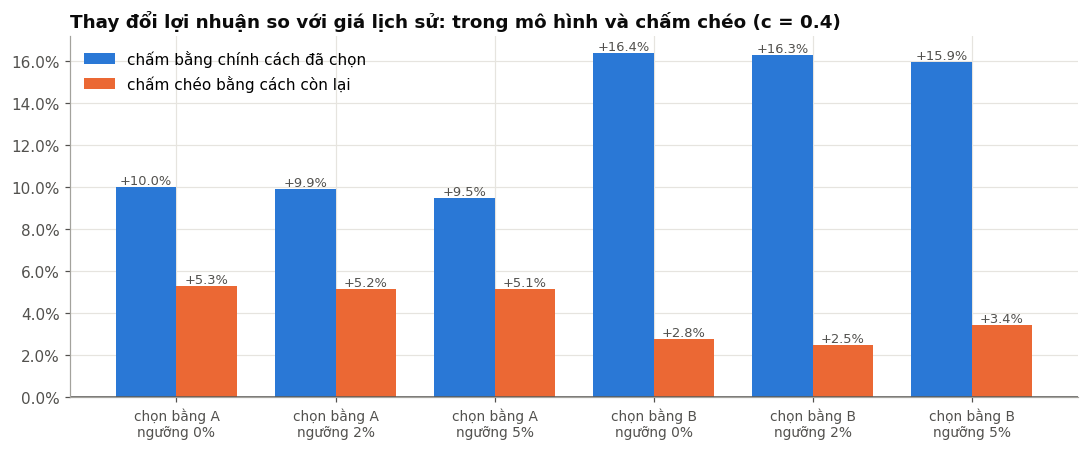

Chính sách vững nhất khi chấm chéo: chọn bằng A, ngưỡng 0% → trong mô hình +10.0%, chấm chéo +5.3%


In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
labels, inm, crs = [], [], []
for sel in ["A", "B"]:
    for mg in MIN_GAINS:
        r = main[(main["chọn bằng"] == sel) & (main.ngưỡng == mg)].iloc[0]
        labels.append(f"chọn bằng {sel}\nngưỡng {mg:.0%}"); inm.append(r["Δπ trong mô hình"]); crs.append(r["Δπ chéo"])
x = np.arange(len(labels)); w = 0.38
for k, (vals, col, name) in enumerate([(inm, C1, "chấm bằng chính cách đã chọn"), (crs, C2, "chấm chéo bằng cách còn lại")]):
    bars = ax.bar(x + (k - 0.5) * w, vals, width=w, color=col, label=name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, pct(v), ha="center", va="bottom" if v >= 0 else "top", fontsize=8.5, color=INK2)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, labels, fontsize=9); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f"Thay đổi lợi nhuận so với giá lịch sử: trong mô hình và chấm chéo (c = {MAIN_COST})")
ax.legend(loc="upper left")
save(fig, "res_cross_evaluation")

best_cross = main.loc[main["Δπ chéo"].idxmax()]
print(f"Chính sách vững nhất khi chấm chéo: chọn bằng {best_cross['chọn bằng']}, ngưỡng {best_cross['ngưỡng']:.0%} → "
      f"trong mô hình {pct(best_cross['Δπ trong mô hình'])}, chấm chéo {pct(best_cross['Δπ chéo'])}")

## 2. Độ vững theo giá vốn

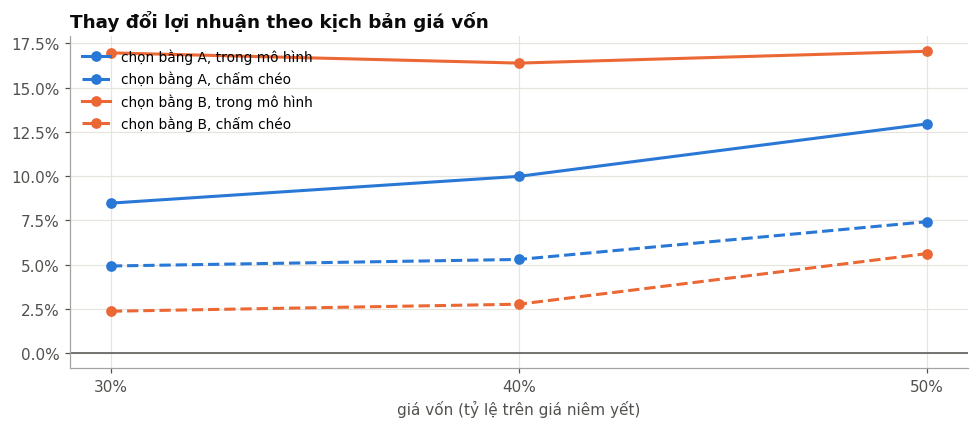

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for sel, col in [("A", C1), ("B", C2)]:
    s = cross[(cross["chọn bằng"] == sel) & (cross.ngưỡng == 0.0)].sort_values("c")
    ax.plot(s.c, s["Δπ trong mô hình"], marker="o", color=col, label=f"chọn bằng {sel}, trong mô hình")
    ax.plot(s.c, s["Δπ chéo"], marker="o", ls="--", color=col, label=f"chọn bằng {sel}, chấm chéo")
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(COSTS, [f"{c:.0%}" for c in COSTS]); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("giá vốn (tỷ lệ trên giá niêm yết)"); ax.set_title("Thay đổi lợi nhuận theo kịch bản giá vốn")
ax.legend(fontsize=9)
save(fig, "res_cost_sensitivity")

## 3. Bảng tổng hợp kết quả cho báo cáo

In [5]:
T = OUT_DIR / "tables"
def read(name):
    p = T / name
    return pd.read_csv(p) if p.exists() else None

eda = json.load(open(T / "eda_summary.json", encoding="utf-8"))
prep = json.load(open(T / "prep_log.json", encoding="utf-8"))
fc = read("fc_summary.csv"); opt = read("opt_summary.csv"); met = read("table_4_metrics.csv")
e = eda["elasticity_overall"]
rows = [
    ("RQ1", "Độ co giãn tổng thể (fixed effects, KTC 95%)", f"{e['elasticity']:.2f} ({e['ci_low']:.2f} đến {e['ci_high']:.2f})"),
    ("RQ1", "Số ngành theo nhóm co giãn", "; ".join(f"{k}: {len(v)}" for k, v in eda["elasticity_groups"].items())),
    ("Dữ liệu", "Cầu tăng thêm nhờ khôi phục / dòng bị loại", f"{prep['censoring']['total_uplift_from_recovery']:+.1%} / {prep['censoring']['share_rows_heavy_stockout_excluded']:.1%}"),
]
if fc is not None:
    for _, r in fc.iterrows():
        rows.append(("RQ2", r["Chỉ tiêu"], r["Kết quả"]))
if opt is not None:
    for _, r in opt.iterrows():
        rows.append(("RQ3", r["Chỉ tiêu"], r["Kết quả"]))
for sel in ["A", "B"]:
    r = main[(main["chọn bằng"] == sel) & (main.ngưỡng == 0.0)].iloc[0]
    rows.append(("RQ3", f"Chọn bằng {sel}: Δ lợi nhuận trong mô hình / chấm chéo (c = {MAIN_COST})",
                 f"{pct(r['Δπ trong mô hình'])} / {pct(r['Δπ chéo'])}"))
final = pd.DataFrame(rows, columns=["Câu hỏi", "Chỉ tiêu", "Kết quả"])
final.to_csv(T / "table_final_summary.csv", index=False)
final

,Câu hỏi,Chỉ tiêu,Kết quả
0,RQ1,"Độ co giãn tổng thể (fixed effects, KTC 95%)",-2.01 (-2.06 đến -1.96)
1,RQ1,Số ngành theo nhóm co giãn,Chưa kết luận: 4; Rất co giãn: 8; Co giãn vừa:...
2,Dữ liệu,Cầu tăng thêm nhờ khôi phục / dòng bị loại,+20.4% / 15.1%
3,RQ2,WAPE test: LightGBM vs MA7,32.13% vs 34.96% (giảm 8.1%)
4,RQ2,Hàm mục tiêu được chọn,tweedie
5,RQ2,Biến giá trong tổng gain,2.1%
6,RQ2,Độ co giãn: LightGBM vs fixed effects,-0.99 vs -2.01
7,RQ2,Tương quan độ co giãn theo ngành,r = 0.51 (22 ngành)
8,RQ2,Vi phạm đơn điệu,0.00%
9,RQ3,"Δ lợi nhuận vs giá lịch sử (c = 0,4)",A: +10.0% | B: +16.4%


## 4. Xuất dữ liệu cho demo Streamlit

Demo chỉ cần một tập nhỏ: các sản phẩm bán chạy nhất, mỗi sản phẩm vài chục cửa hàng, cùng bảng tổng quan tính sẵn trên toàn bộ tập test. Thư mục `demo/` sau đó gồm `app.py`, `requirements.txt` và `data/`, đẩy lên GitHub là chạy được trên Streamlit Community Cloud.

In [6]:
top_products = rec.groupby("product_id").q_base.sum().nlargest(DEMO_PRODUCTS).index
sub = rec[rec.product_id.isin(top_products)]
keep_stores = (sub.groupby(["product_id", "store_id"]).q_base.sum().reset_index()
               .sort_values("q_base", ascending=False).groupby("product_id").head(DEMO_STORES_PER_PRODUCT))
demo = sub.merge(keep_stores[["product_id", "store_id"]], on=["product_id", "store_id"])
demo_cols = (["store_id", "product_id", "first_category_id", "dt", "discount", "el_group", "E", "q_base"] +
             [f"qA_{d:.2f}" for d in GRID] + [f"qB_{d:.2f}" for d in GRID] + [f"allowed_{d:.2f}" for d in GRID])
demo[demo_cols].to_parquet(DEMO_DIR / "demo_data.parquet", index=False)

# Bảng tổng quan tính trên TOÀN BỘ tập test cho nhiều mức giá vốn (demo chỉ việc tra)
ov = []
for c in np.round(np.arange(0.20, 0.651, 0.05), 2):
    for sel, Qsel in MODELS.items():
        for mg in MIN_GAINS:
            j = policy(Qsel, c, mg); d = GRID[j]
            ov.append({"c": c, "cách": sel, "ngưỡng": mg, "Δπ_A": score(j, QA, c), "Δπ_B": score(j, QB, c),
                       "ngày_giảm": (d < 0.995).mean(), **{f"share_{dd:.2f}": (d == dd).mean() for dd in GRID}})
pd.DataFrame(ov).to_csv(DEMO_DIR / "portfolio_summary.csv", index=False)
json.dump({**cfg, "min_gains": MIN_GAINS, "hist_discount_days": float((d0 < 0.995).mean()),
           "n_rows_full": int(len(rec))}, open(DEMO_DIR / "config.json", "w"), indent=2)
size_mb = (DEMO_DIR / "demo_data.parquet").stat().st_size / 1e6
print(f"demo_data.parquet: {len(demo):,} dòng, {demo.product_id.nunique()} sản phẩm, {size_mb:.1f} MB → {DEMO_DIR}")

demo_data.parquet: 13,062 dòng, 40 sản phẩm, 1.2 MB → /content/drive/MyDrive/Dynamic_Pricing_Project/demo/data


In [7]:
m = (rec.discount >= 0.3).to_numpy()
print(f"Dòng test có discount < 0.3: {(~m).sum():,} ({(~m).mean():.2%})")
for sel, Qs, Qe in [("A", QA, QB), ("B", QB, QA)]:
    j = policy(Qs, 0.4, 0.05); d = GRID[j]; idx = np.arange(len(j))
    den = ((d0 - 0.4) * base)[m].sum()
    f = lambda Q: ((d - 0.4) * Q[idx, j])[m].sum() / den - 1
    print(f"chọn bằng {sel}, ngưỡng 5%: trong mô hình {f(Qs):+.1%} | chấm chéo {f(Qe):+.1%}")

Dòng test có discount < 0.3: 0 (0.00%)
chọn bằng A, ngưỡng 5%: trong mô hình +9.5% | chấm chéo +5.1%
chọn bằng B, ngưỡng 5%: trong mô hình +15.9% | chấm chéo +3.4%
